In [75]:
import os
import shutil
import numpy as np
import re
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics.pairwise import cosine_similarity
from torchvision import models, transforms
import pandas as pd
import cv2




In [76]:
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else
                      ("cuda" if torch.cuda.is_available() else "cpu"))

print("Using:", DEVICE)

Using: mps


In [77]:
# Dataset Yamaha
A_TRAIN_DIR = "../data/yamaha_v0/train"
A_VAL_DIR   = "../data/yamaha_v0/valid"

# Dataset Kaggle 
B_TRAIN_RGB  = "../data/dataset/train/rgb"
B_TRAIN_MASK = "../data/dataset/train/mask" 
B_VAL_RGB    = "../data/dataset/val/rgb"
B_VAL_MASK   = "../data/dataset/val/mask"

# Folders for converted masks of B
B_CONV_TRAIN = "../data/dataset/train/mask_converted"
B_CONV_VAL   = "../data/dataset/val/mask_converted"
os.makedirs(B_CONV_TRAIN, exist_ok=True)
os.makedirs(B_CONV_VAL, exist_ok=True)

# Final unified dataset
UNIFIED_ROOT = "../data/unified_dataset"
UNIFIED_TRAIN_IMG  = os.path.join(UNIFIED_ROOT, "train", "images")
UNIFIED_TRAIN_MASK = os.path.join(UNIFIED_ROOT, "train", "masks")
UNIFIED_VAL_IMG    = os.path.join(UNIFIED_ROOT, "val", "images")
UNIFIED_VAL_MASK   = os.path.join(UNIFIED_ROOT, "val", "masks")

for d in [UNIFIED_TRAIN_IMG, UNIFIED_TRAIN_MASK, UNIFIED_VAL_IMG, UNIFIED_VAL_MASK]:
    os.makedirs(d, exist_ok=True)


In [78]:
# Class maps for datasets A and B 

CLASS_MAP_A = {
    (255, 255, 255): "background",
    (1, 88, 255): "sky",
    (156, 76, 30): "rough_trail",
    (178, 176, 153): "smooth_trail",
    (128, 255, 0): "traversable_grass",
    (40, 80, 0): "high_vegetation",
    (0, 160, 0): "non_traversable_low_vegetation",
    (255, 0, 128): "puddle",
    (255, 0, 0): "obstacle"
}

CLASS_MAP_B = {
    (0, 0, 223): "sky",
    (75, 255, 10): "traversable_grass",
    (0, 0, 0): "high_vegetation",
    (207, 149, 30): "smooth_trail",
    (255, 255, 255): "obstacle"
}

MAP_B_TO_A = {
    "sky": "sky",
    "traversable_grass": "traversable_grass",
    "high_vegetation": "high_vegetation",
    "smooth_trail": "smooth_trail",
    "obstacle": "obstacle"
}

COLOR_LIST = list(CLASS_MAP_A.keys())
CLASS_NAMES = list(CLASS_MAP_A.values())
NUM_CLASSES = len(COLOR_LIST)


In [79]:
# Function to convert masks from dataset B to the color scheme of dataset A
def convert_B_masks(src_mask_dir, dst_mask_dir):
    os.makedirs(dst_mask_dir, exist_ok=True)
    files = [f for f in os.listdir(src_mask_dir) if f.endswith(".png")]
    for fname in tqdm(files, desc=f"Converting masks in {src_mask_dir}"):
        mask = np.array(Image.open(os.path.join(src_mask_dir, fname)).convert("RGB"))
        converted = np.zeros_like(mask)
        for color_b, cls_b in CLASS_MAP_B.items():
            cls_A = MAP_B_TO_A[cls_b]
            color_A = [c for c, v in CLASS_MAP_A.items() if v == cls_A][0]
            converted[(mask == color_b).all(axis=-1)] = color_A
        Image.fromarray(converted.astype(np.uint8)).save(os.path.join(dst_mask_dir, fname))

convert_B_masks(B_TRAIN_MASK, B_CONV_TRAIN)
convert_B_masks(B_VAL_MASK,   B_CONV_VAL)

Converting masks in ../data/dataset/val/mask: 100%|██████████| 1234/1234 [00:42<00:00, 29.07it/s]


In [80]:
#Dataset A copy function

import os, shutil
from tqdm import tqdm

def copy_yamaha_split(src_root, out_img_dir, out_mask_dir, prefix):
    folders = [f for f in os.listdir(src_root) if os.path.isdir(os.path.join(src_root, f))]

    for folder in tqdm(folders, desc=f"Copying Yamaha {prefix}"):
        fpath = os.path.join(src_root, folder)

        img_file = None
        mask_file = None

        for f in os.listdir(fpath):
            if f.lower().endswith(".jpg") and "label" not in f:
                img_file = f
            if f.lower().endswith(".png") and ("label" in f or "mask" in f):
                mask_file = f

        if img_file is None or mask_file is None:
            continue

        new_name = f"{prefix}_{folder}"

        shutil.copy2(os.path.join(fpath, img_file),
                     os.path.join(out_img_dir, new_name + ".jpg"))
        shutil.copy2(os.path.join(fpath, mask_file),
                     os.path.join(out_mask_dir, new_name + ".png"))


In [81]:
def copy_B_split(rgb_dir, conv_mask_dir, out_img_dir, out_mask_dir, prefix):
    rgb_files  = sorted([f for f in os.listdir(rgb_dir) if f.startswith("rgb_")])
    mask_files = set(os.listdir(conv_mask_dir))

    copied = 0
    missing = 0

    for f in tqdm(rgb_files, desc=f"Copying B {prefix}"):
        match = re.search(r"rgb_(\d+)\.png", f)
        if not match:
            missing += 1
            continue

        number = match.group(1)  
        mask_name = f"segmentation_{number}.png"

        if mask_name not in mask_files:
            missing += 1
            continue

        new_name = f"{prefix}_{number}"

        shutil.copy2(os.path.join(rgb_dir, f),
                     os.path.join(out_img_dir, new_name + ".png"))

        shutil.copy2(os.path.join(conv_mask_dir, mask_name),
                     os.path.join(out_mask_dir, new_name + ".png"))

        copied += 1

In [82]:
# Yamaha Train
copy_yamaha_split(A_TRAIN_DIR, UNIFIED_TRAIN_IMG, UNIFIED_TRAIN_MASK, prefix="Atrain")

# Yamaha Validation
copy_yamaha_split(A_VAL_DIR, UNIFIED_VAL_IMG, UNIFIED_VAL_MASK, prefix="Aval")

# Dataset B Train
copy_B_split(B_TRAIN_RGB, B_CONV_TRAIN, UNIFIED_TRAIN_IMG, UNIFIED_TRAIN_MASK, prefix="Btrain")

# Dataset B Validation
copy_B_split(B_VAL_RGB, B_CONV_VAL, UNIFIED_VAL_IMG, UNIFIED_VAL_MASK, prefix="Bval")

Copying B Bval: 100%|██████████| 1234/1234 [00:04<00:00, 277.76it/s]


In [83]:
def count_unified(unified_train_img, unified_train_mask,
                  unified_val_img, unified_val_mask):

    def count_files(path, exts):
        return len([f for f in os.listdir(path) if f.lower().endswith(exts)])

    train_imgs  = count_files(unified_train_img, (".jpg", ".png"))
    train_masks = count_files(unified_train_mask, (".png",))

    val_imgs    = count_files(unified_val_img, (".jpg", ".png"))
    val_masks   = count_files(unified_val_mask, (".png",))

    print("========== UNIFIED TRAIN ==========")
    print("Images:", train_imgs)
    print("Masks :", train_masks)

    print("\n========== UNIFIED VAL ==========")
    print("Images:", val_imgs)
    print("Masks :", val_masks)


In [84]:
UNIFIED_TRAIN_IMG  = "../data/unified_dataset/train/images"
UNIFIED_TRAIN_MASK = "../data/unified_dataset/train/masks"
UNIFIED_VAL_IMG    = "../data/unified_dataset/val/images"
UNIFIED_VAL_MASK   = "../data/unified_dataset/val/masks"

In [85]:
count_unified(
    UNIFIED_TRAIN_IMG, UNIFIED_TRAIN_MASK,
    UNIFIED_VAL_IMG, UNIFIED_VAL_MASK
)

========== UNIFIED TRAIN ==========
Images: 4633
Masks : 4633

========== UNIFIED VAL ==========
Images: 1379
Masks : 1379


In [86]:
device = torch.device("mps" if torch.backends.mps.is_available()
                      else ("cuda" if torch.cuda.is_available() else "cpu"))

# ResNet18 feature extractor
model_resnet = models.resnet18(pretrained=True)
model_resnet = torch.nn.Sequential(*list(model_resnet.children())[:-1])
model_resnet.eval().to(device)

preprocess = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

/opt/anaconda3/envs/bert_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/anaconda3/envs/bert_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [87]:
#ResNet18 duplicate removal function

def remove_and_show_duplicates(img_dir, mask_dir, threshold=0.95, show_max=10):
   
    features = [ ]
    names = [ ]

    img_files = sorted([f for f in os.listdir(img_dir)
                        if f.lower().endswith((".jpg", ".png"))])

    for fname in tqdm(img_files):
        img_path = os.path.join(img_dir, fname)
        img = Image.open(img_path).convert("RGB")
        x = preprocess(img).unsqueeze(0).to(device)

        with torch.no_grad():
            feat = model_resnet(x).cpu().numpy().flatten()
        
        features.append(feat)
        names.append(fname)

    features = np.array(features)

    sim_matrix = cosine_similarity(features)

    duplicates = [ ]    

    N = len(names)
    for i in range(N):
        for j in range(i + 1, N):
            sim = sim_matrix[i, j]
            if sim > threshold:
                duplicates.append((names[i], names[j], sim))

    print(f"\n Found {len(duplicates)} duplicate couples (sim>{threshold})")

    show_limit = min(show_max, len(duplicates))

    for idx in range(show_limit):
        fname1, fname2, sim = duplicates[idx]

        img1 = np.array(Image.open(os.path.join(img_dir, fname1)))
        img2 = np.array(Image.open(os.path.join(img_dir, fname2)))

        plt.figure(figsize=(8,4))
        plt.suptitle(f"Similarity = {sim:.3f}", fontsize=14)

        plt.subplot(1,2,1)
        plt.imshow(img1)
        plt.title(f"KEEP: {fname1}")
        plt.axis("off")

        plt.subplot(1,2,2)
        plt.imshow(img2)
        plt.title(f"REMOVE: {fname2}")
        plt.axis("off")

        plt.show()

    removed = 0
    to_remove = set([pair[1] for pair in duplicates])


    for fname in to_remove:
        img_path = os.path.join(img_dir, fname)
        mask_path = os.path.join(mask_dir, fname.replace(".jpg",".png").replace(".jpeg",".png"))

        if os.path.exists(img_path):
            os.remove(img_path)
        if os.path.exists(mask_path):
            os.remove(mask_path)

        removed += 1

    print(f"✅ Removed {removed} duplicate images from the dataset")

    return duplicates

100%|██████████| 4633/4633 [01:17<00:00, 59.43it/s]



 Found 2050 duplicate couples (sim>0.95)


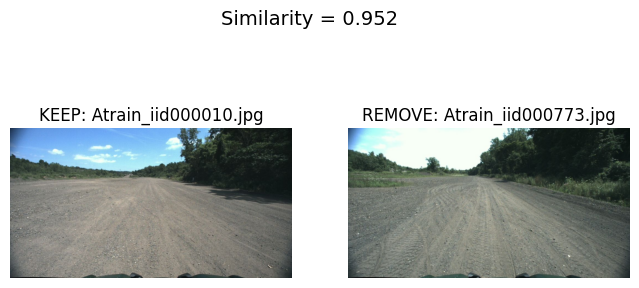

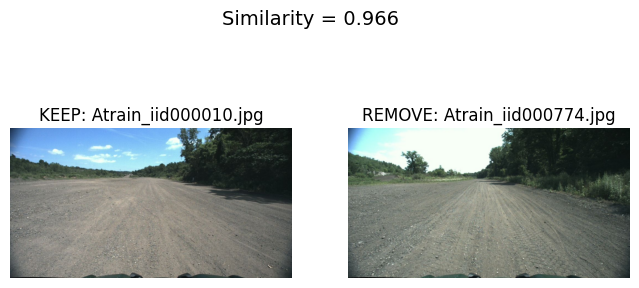

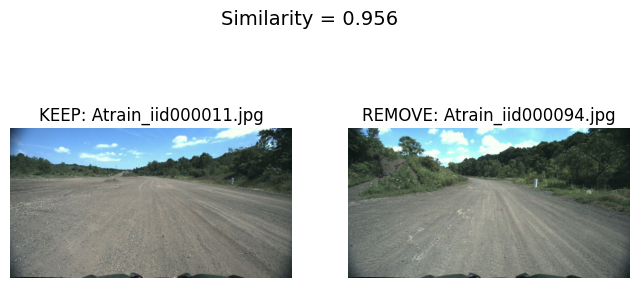

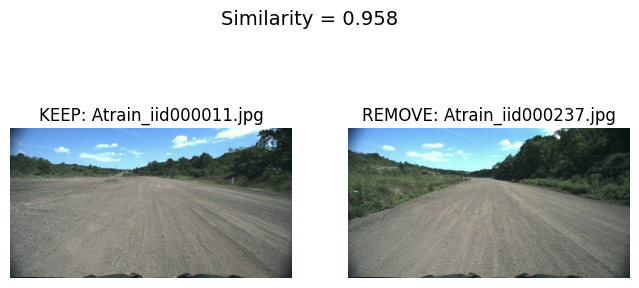

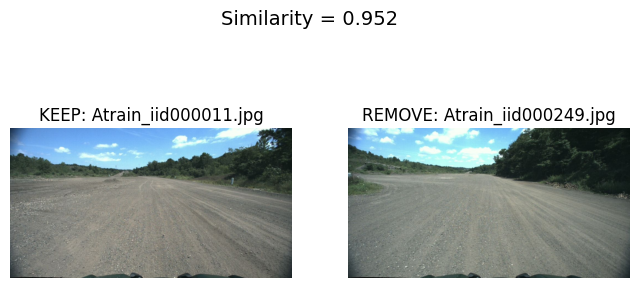

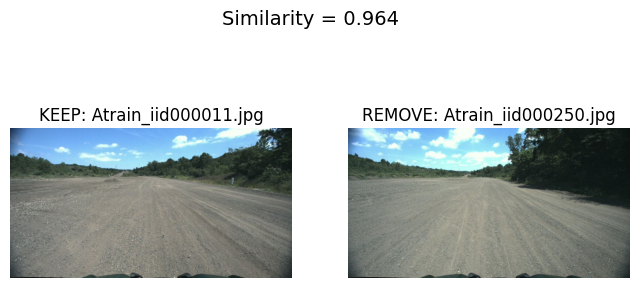

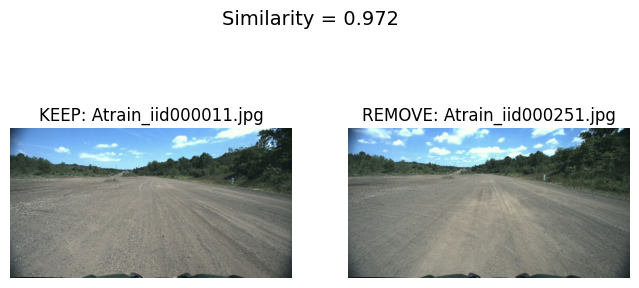

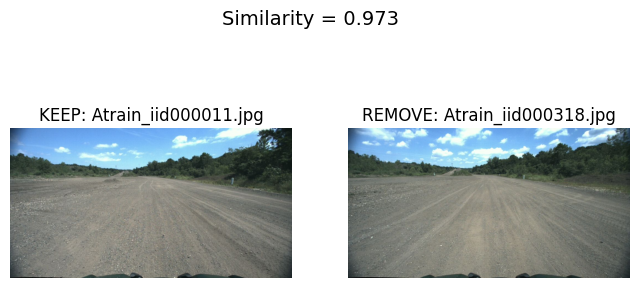

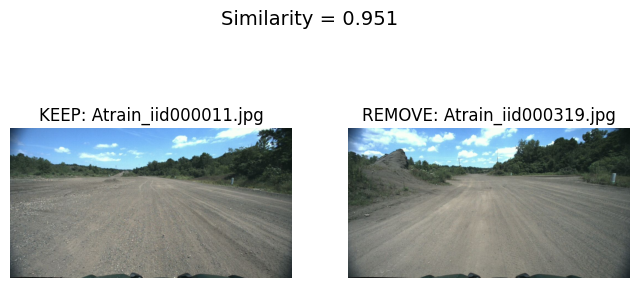

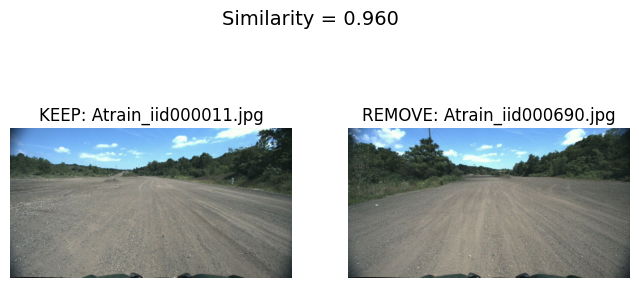

✅ Removed 1108 duplicate images from the dataset


In [88]:
duplicates_train = remove_and_show_duplicates(
    UNIFIED_TRAIN_IMG, UNIFIED_TRAIN_MASK,
    threshold=0.95,
    show_max=10
)

100%|██████████| 1379/1379 [00:24<00:00, 55.68it/s]



 Found 169 duplicate couples (sim>0.95)


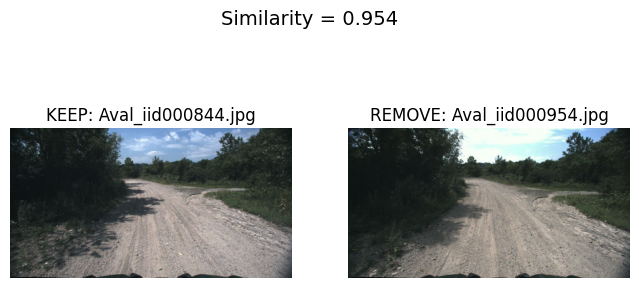

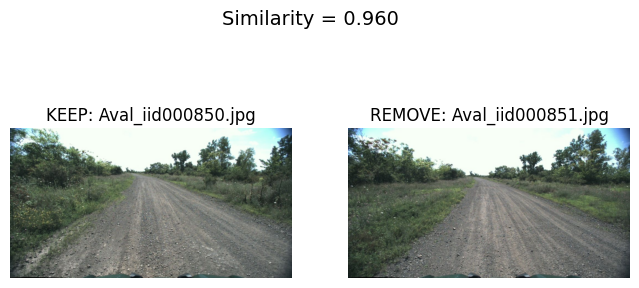

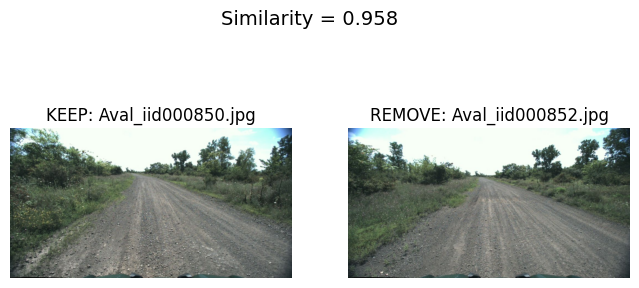

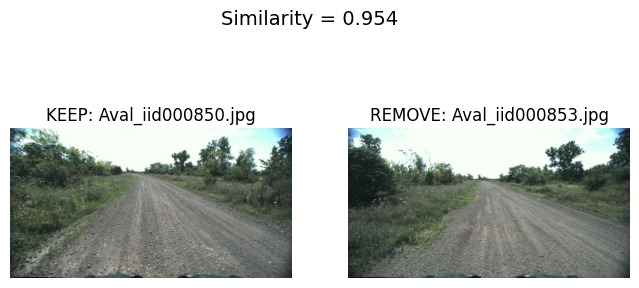

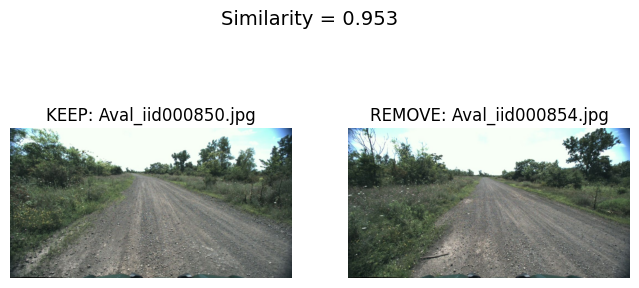

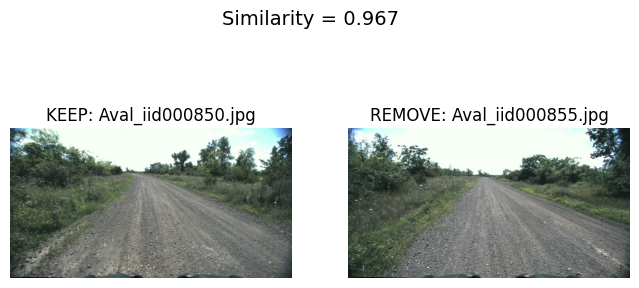

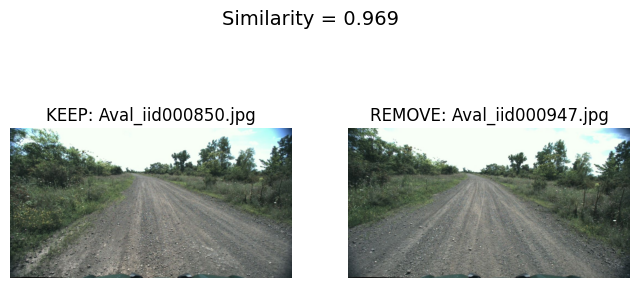

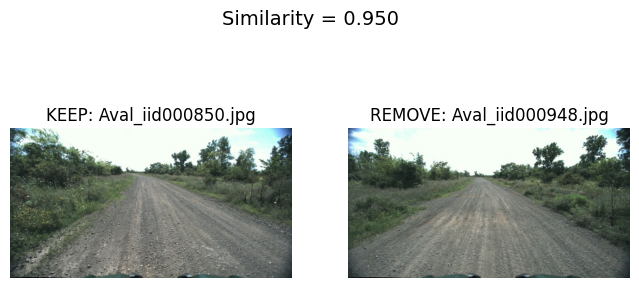

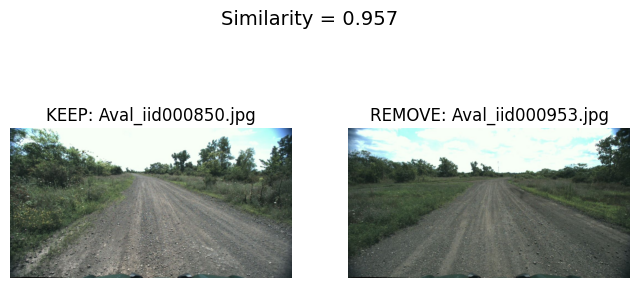

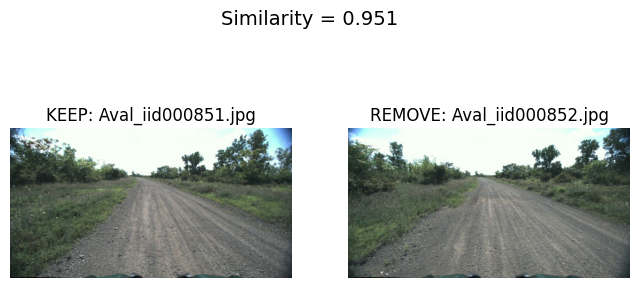

✅ Removed 126 duplicate images from the dataset


In [89]:
duplicates_val = remove_and_show_duplicates(
    UNIFIED_VAL_IMG, UNIFIED_VAL_MASK,
    threshold=0.95,
    show_max=10
)

In [90]:
count_unified(
    UNIFIED_TRAIN_IMG, UNIFIED_TRAIN_MASK,
    UNIFIED_VAL_IMG, UNIFIED_VAL_MASK
)

========== UNIFIED TRAIN ==========
Images: 3525
Masks : 3525

========== UNIFIED VAL ==========
Images: 1253
Masks : 1253


In [91]:
MASK_DIR = UNIFIED_TRAIN_MASK

In [92]:
pixel_counts = {cls: 0 for cls in CLASS_NAMES}

mask_files = [f for f in os.listdir(MASK_DIR) if f.endswith(".png")]

for fname in tqdm(mask_files):
    mask = np.array(Image.open(os.path.join(MASK_DIR, fname)).convert("RGB"))
    
    for color, cls_name in CLASS_MAP_A.items():
        pixel_counts[cls_name] += np.sum(np.all(mask == np.array(color), axis=-1))

100%|██████████| 3525/3525 [02:20<00:00, 25.02it/s]


In [93]:
df = pd.DataFrame({
    "class": CLASS_NAMES,
    "pixels": [pixel_counts[c] for c in CLASS_NAMES]
})

df["percentage"] = 100 * df["pixels"] / df["pixels"].sum()

# Inverse frequency weights
df["inv_freq"] = 1 / (df["pixels"] + 1e-6)

# Log-inverse weights 
df["log_inv"] = -np.log((df["pixels"] / df["pixels"].sum()) + 1e-6)

#Normalized weights
df["log_inv_norm"] = df["log_inv"] / df["log_inv"].mean()

df

,class,pixels,percentage,inv_freq,log_inv,log_inv_norm
0,background,10111948,0.772748,9.889291e-08,4.862844,1.456707
1,sky,407120209,31.111825,2.456277e-09,1.167579,0.349758
2,rough_trail,57033608,4.358466,1.753352e-08,3.133027,0.938525
3,smooth_trail,215535784,16.471085,4.639601e-09,1.803558,0.540271
4,traversable_grass,320787519,24.514345,3.117328e-09,1.405908,0.421152
5,high_vegetation,261059616,19.949983,3.830543e-09,1.611937,0.482870
6,non_traversable_low_vegetation,24436029,1.867383,4.092318e-08,3.980579,1.192416
7,puddle,833080,0.063663,1.200365e-06,7.357747,2.204076
8,obstacle,11652831,0.890501,8.581606e-08,4.721029,1.414225


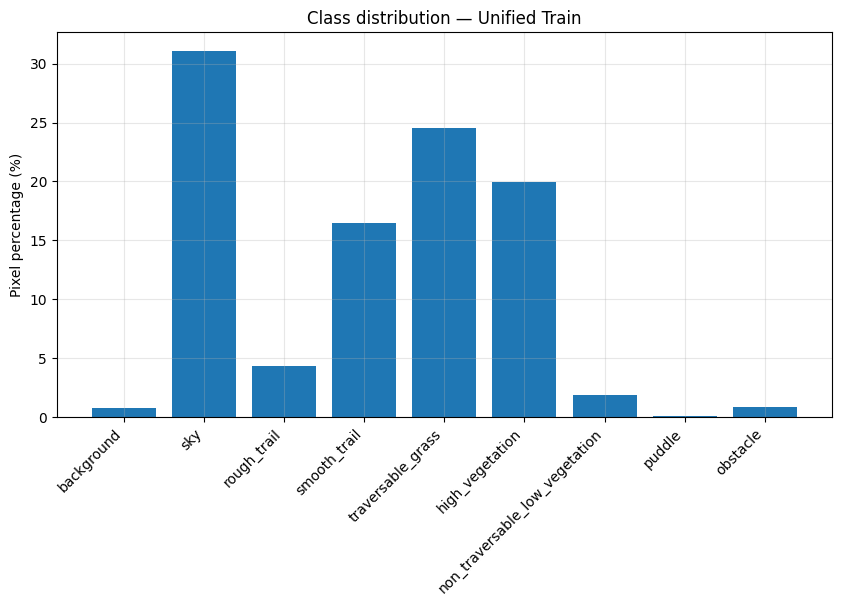

In [94]:
plt.figure(figsize=(10,5))
plt.bar(df["class"], df["percentage"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Pixel percentage (%)")
plt.title("Class distribution — Unified Train")
plt.grid(alpha=0.3)
plt.show()

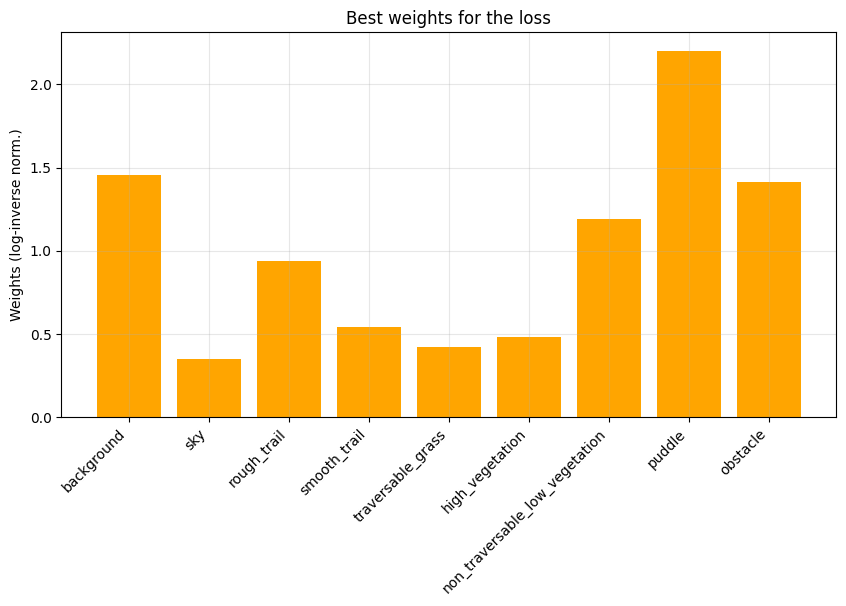

In [95]:
plt.figure(figsize=(10,5))
plt.bar(df["class"], df["log_inv_norm"], color="orange")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Weights (log-inverse norm.)")
plt.title("Best weights for the loss")
plt.grid(alpha=0.3)
plt.show()

In [96]:
RARE_CLASSES = {
    "puddle",
    "obstacle",
    "non_traversable_low_vegetation"
}

In [97]:
def compute_rare_percentage(mask_rgb):
    total = mask_rgb.shape[0] * mask_rgb.shape[1]
    rare_pixels = 0
    
    for color, cls in CLASS_MAP_A.items():
        if cls in RARE_CLASSES:
            rare_pixels += np.sum(np.all(mask_rgb == np.array(color), axis=-1))
    
    return rare_pixels / total

In [98]:
def rotate_image(image, angle_deg):
    h, w = image.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), angle_deg, 1.0)
    rotated = cv2.warpAffine(
        image, M, (w, h),
        flags=cv2.INTER_LINEAR,
        borderValue=(0, 0, 0)
    )
    return rotated

In [99]:
def rotate_mask(mask, angle_deg):
    h, w = mask.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), angle_deg, 1.0)
    rotated = cv2.warpAffine(
        mask, M, (w, h),
        flags=cv2.INTER_NEAREST,
        borderValue=(0, 0, 0)
    )
    return rotated

In [100]:
def largest_rectangle_no_black(rotated):
  
    mask_valid = np.any(rotated != [0,0,0], axis=-1).astype(np.uint8)

    h, w = mask_valid.shape
    height = [0] * w
    max_area = 0
    best = (0,0,0,0)

    for i in range(h):
        for j in range(w):
            height[j] = height[j] + 1 if mask_valid[i, j] else 0

        stack = []
        j = 0

        while j <= w:
            cur_h = height[j] if j < w else 0
            if not stack or cur_h >= height[stack[-1]]:
                stack.append(j)
                j += 1
            else:
                top = stack.pop()
                width = j if not stack else j - stack[-1] - 1
                area = height[top] * width
                if area > max_area:
                    max_area = area
                    y2 = i + 1
                    y1 = y2 - height[top]
                    x2 = j
                    x1 = x2 - width
                    best = (y1, y2, x1, x2)

    return best  # y1, y2, x1, x2

In [101]:
def auto_crop(rotated_img, rotated_mask):
    y1, y2, x1, x2 = largest_rectangle_no_black(rotated_img)
    img_crop  = rotated_img[y1:y2, x1:x2]
    mask_crop = rotated_mask[y1:y2, x1:x2]
    return img_crop, mask_crop

In [102]:
def rotate_and_autocrop(image, mask, max_angle=180):
    angle = np.random.uniform(-max_angle, max_angle)

    img_rot  = rotate_image(image, angle)
    mask_rot = rotate_mask(mask, angle)

    img_final, mask_final = auto_crop(img_rot, mask_rot)
    return img_final, mask_final

In [103]:
def generate_rotations_no_black(image, mask, n_aug=5):
    imgs = [ ]
    masks =  [ ]
    for _ in range(n_aug):
        img_aug, mask_aug = rotate_and_autocrop(image, mask)
        imgs.append(img_aug)
        masks.append(mask_aug)
    return imgs, masks

In [ ]:
def show_example_for_n_rotations(img_dir, mask_dir, n_aug):
    for fname in sorted(os.listdir(mask_dir)):
        if not fname.endswith(".png"):
            continue

        mask = np.array(Image.open(os.path.join(mask_dir, fname)).convert("RGB"))
        rare_pct = compute_rare_percentage(mask)

    
        if rare_pct > 0.50: expected = 25
        elif rare_pct > 0.40: expected = 20
        elif rare_pct > 0.30: expected = 15
        elif rare_pct > 0.20: expected = 10
        elif rare_pct > 0.10: expected = 5
        else: expected = 0

        if expected != n_aug:
            continue

        
        img_path = os.path.join(img_dir, fname.replace(".png", ".jpg"))
        if not os.path.exists(img_path):
            img_path = os.path.join(img_dir, fname)

        img = np.array(Image.open(img_path).convert("RGB"))

    
        imgs_aug, masks_aug = generate_rotations_no_black(img, mask, n_aug)

        cols = n_aug + 1
        plt.figure(figsize=(4*cols, 7))

        plt.subplot(2, cols, 1)
        plt.imshow(img)
        plt.title(f"ORIGINAL ({rare_pct:.2%})")
        plt.axis("off")

        plt.subplot(2, cols, cols+1)
        plt.imshow(mask)
        plt.title("MASK ORIGINAL")
        plt.axis("off")

        for i in range(n_aug):
            plt.subplot(2, cols, 2+i)
            plt.imshow(imgs_aug[i])
            plt.title(f"AUG {i+1}")
            plt.axis("off")

            plt.subplot(2, cols, cols+2+i)
            plt.imshow(masks_aug[i])
            plt.title(f"MASK AUG {i+1}")
            plt.axis("off")

        plt.tight_layout()
        plt.show()
        return 


   EXAMPLE WITH 5 AUGMENTATIONS


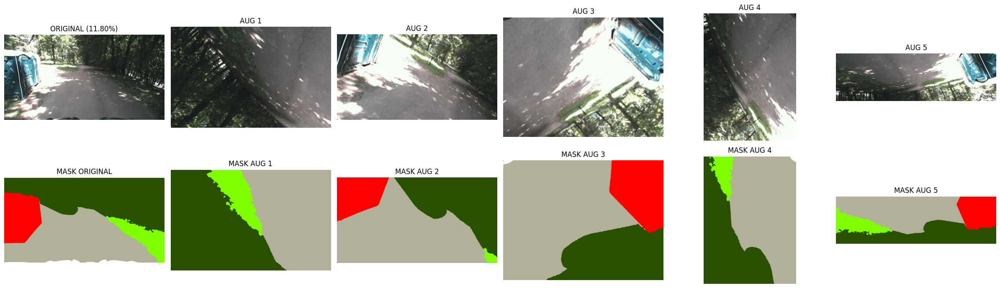

In [105]:
for n in [5]:
    print("\n==============================")
    print(f"   EXAMPLE WITH {n} AUGMENTATIONS")
    print("==============================")
    show_example_for_n_rotations(UNIFIED_TRAIN_IMG, UNIFIED_TRAIN_MASK, n)

In [106]:
def augment_and_save_no_black(img_dir, mask_dir):
    created = 0

    for fname in tqdm(sorted(os.listdir(mask_dir)), desc="Augmenting and saving"):
        if not fname.endswith(".png"):
            continue

        mask_path = os.path.join(mask_dir, fname)
        img_path = os.path.join(img_dir, fname.replace(".png", ".jpg"))
        if not os.path.exists(img_path):
            img_path = os.path.join(img_dir, fname)  # maybe PNG

      
        mask = np.array(Image.open(mask_path).convert("RGB"))
        img  = np.array(Image.open(img_path).convert("RGB"))

        rare_pct = compute_rare_percentage(mask)

    
        if rare_pct > 0.50: n_aug = 25
        elif rare_pct > 0.40: n_aug = 20
        elif rare_pct > 0.30: n_aug = 15
        elif rare_pct > 0.20: n_aug = 10
        elif rare_pct > 0.10: n_aug = 5
        else: n_aug = 0

        if n_aug == 0:
            continue

     
        for i in range(n_aug):
            img_aug, mask_aug = rotate_and_autocrop(img, mask)   

            base = fname.replace(".png","")
            out_img  = os.path.join(img_dir,  f"{base}_AUG_{i}.png")
            out_mask = os.path.join(mask_dir, f"{base}_AUG_{i}.png")

            Image.fromarray(img_aug.astype(np.uint8)).save(out_img)
            Image.fromarray(mask_aug.astype(np.uint8)).save(out_mask)

            created += 1

    print(f"\n✨  {created} augmented images saved")

In [107]:
augment_and_save_no_black(UNIFIED_TRAIN_IMG, UNIFIED_TRAIN_MASK)

Augmenting and saving: 100%|██████████| 3525/3525 [07:38<00:00,  7.68it/s] 


✨  2015 augmented images saved


In [111]:
def compute_class_stats_from_masks(mask_dir):
    pixel_counts = {cls: 0 for cls in CLASS_NAMES}

    for fname in os.listdir(mask_dir):
        if not fname.endswith(".png"):
            continue

        mask = np.array(Image.open(os.path.join(mask_dir, fname)).convert("RGB"))

        for color, cls in CLASS_MAP_A.items():
            pixel_counts[cls] += np.sum(np.all(mask == np.array(color), axis=-1))

    total_pixels = sum(pixel_counts.values())

    df = pd.DataFrame({
        "class": pixel_counts.keys(),
        "pixels": pixel_counts.values()
    })

    df["percentage"] = df["pixels"] / total_pixels * 100
    df["inv_freq"] = 1 / (df["pixels"] + 1e-9)
    df["log_inv"] = -np.log(df["pixels"] / total_pixels + 1e-9)
    df["log_inv_norm"] = df["log_inv"] / df["log_inv"].max()

    return df

In [112]:
df_after_aug = compute_class_stats_from_masks(UNIFIED_TRAIN_MASK)
display(df_after_aug)

,class,pixels,percentage,inv_freq,log_inv,log_inv_norm
0,background,19239379,1.090024,5.197673e-08,4.518970,0.707212
1,sky,442233340,25.055120,2.261250e-09,1.384092,0.216608
2,rough_trail,124223220,7.037976,8.050025e-09,2.653850,0.415324
3,smooth_trail,278905907,15.801660,3.585439e-09,1.845055,0.288748
4,traversable_grass,341087526,19.324614,2.931799e-09,1.643791,0.257251
5,high_vegetation,387811403,21.971797,2.578573e-09,1.515411,0.237160
6,non_traversable_low_vegetation,141007266,7.988891,7.091833e-09,2.527118,0.395490
7,puddle,2962676,0.167853,3.375327e-07,6.389836,1.000000
8,obstacle,27571109,1.562065,3.626985e-08,4.159161,0.650903


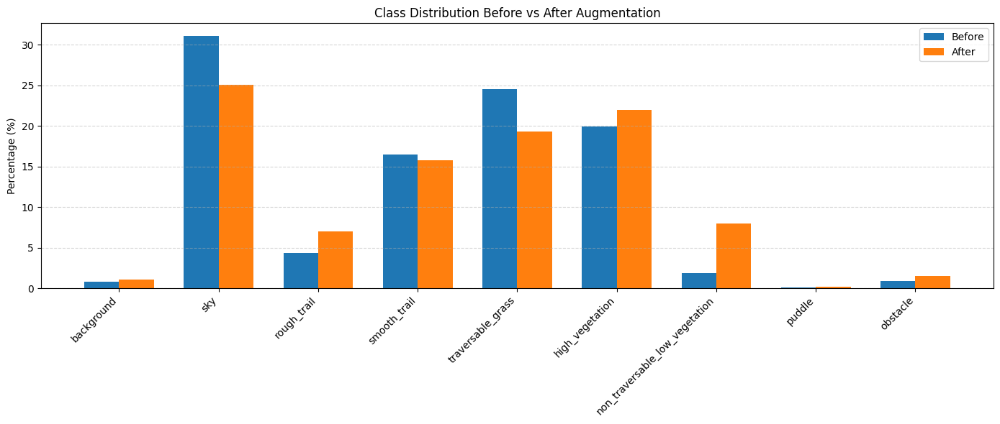

In [113]:

before = pd.DataFrame({
    "class": [
        "background","sky","rough_trail","smooth_trail",
        "traversable_grass","high_vegetation",
        "non_traversable_low_vegetation","puddle","obstacle"
    ],
    "percentage": [
        0.772748,31.111825,4.358466,16.471085,
        24.514345,19.949983,1.867383,0.063663,0.890501
    ]
})


after = pd.DataFrame({
    "class": [
        "background","sky","rough_trail","smooth_trail",
        "traversable_grass","high_vegetation",
        "non_traversable_low_vegetation","puddle","obstacle"
    ],
    "percentage": [
        1.090024,25.055120,7.037976,15.801660,
        19.324614,21.971797,7.988891,0.167853,1.562065
    ]
})


plt.figure(figsize=(14,6))

x = range(len(before))
width = 0.35

plt.bar([i-width/2 for i in x], before["percentage"], width=width, label="Before")
plt.bar([i+width/2 for i in x], after["percentage"], width=width, label="After")

plt.xticks(x, before["class"], rotation=45, ha="right")
plt.ylabel("Percentage (%)")
plt.title("Class Distribution Before vs After Augmentation")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [132]:
def find_corrupted_images(img_dir):
    corrupted = [ ]
    for fname in os.listdir(img_dir):
        path = os.path.join(img_dir, fname)
        # consider only images
        if not fname.lower().endswith((".png",".jpg",".jpeg")):
            continue
        try:
            Image.open(path).verify()
        except:
            corrupted.append(fname)
    return corrupted

corrupted_val = find_corrupted_images(UNIFIED_VAL_IMG)
print("Corrupted validation files:", corrupted_val)

Corrupted validation files: ['Bval_2056.png']


In [133]:
def remove_corrupted(img_dir, mask_dir, corrupted_files):
    removed = 0
    for fname in corrupted_files:
        img_path  = os.path.join(img_dir, fname)
        mask_path = os.path.join(mask_dir, fname.replace(".jpg",".png"))
        
        if os.path.exists(img_path):
            os.remove(img_path)
            removed += 1
        
        if os.path.exists(mask_path):
            os.remove(mask_path)
            removed += 1
    
    print(f"✔ Removed {removed} corrupted image/mask files.")

remove_corrupted(UNIFIED_VAL_IMG, UNIFIED_VAL_MASK, corrupted_val)

✔ Removed 2 corrupted image/mask files.


In [134]:
def resize_dataset(img_dir, mask_dir, final_size=(256,256)):
    img_files = sorted(os.listdir(img_dir))

    for fname in tqdm(img_files, desc="Resizing dataset"):
        if not fname.lower().endswith((".jpg", ".png")):
            continue

        img_path = os.path.join(img_dir, fname)
        mask_path = os.path.join(mask_dir, fname.replace(".jpg", ".png"))

        if not os.path.exists(mask_path):
            continue

       
        img  = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(mask_path).convert("RGB"))


        img_resized  = cv2.resize(img,  final_size, interpolation=cv2.INTER_LINEAR)
        mask_resized = cv2.resize(mask, final_size, interpolation=cv2.INTER_NEAREST)

 
        Image.fromarray(img_resized).save(img_path)
        Image.fromarray(mask_resized).save(mask_path)

In [135]:
resize_dataset(
    img_dir=UNIFIED_TRAIN_IMG,
    mask_dir=UNIFIED_TRAIN_MASK,
    final_size=(256, 256)    
)

Resizing dataset: 100%|██████████| 5540/5540 [00:31<00:00, 176.68it/s]


In [136]:
resize_dataset(UNIFIED_VAL_IMG, UNIFIED_VAL_MASK, final_size=(256,256))

Resizing dataset: 100%|██████████| 1252/1252 [00:12<00:00, 96.58it/s]


In [137]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split

import segmentation_models_pytorch as smp
import torchvision.transforms as T

import matplotlib.pyplot as plt

In [138]:
CLASS_MAP_A = {
    (255,255,255): "background",
    (1,88,255): "sky",
    (156,76,30): "rough_trail",
    (178,176,153): "smooth_trail",
    (128,255,0): "traversable_grass",
    (40,80,0): "high_vegetation",
    (0,160,0): "non_traversable_low_vegetation",
    (255,0,128): "puddle",
    (255,0,0): "obstacle"
}

COLOR_LIST = list(CLASS_MAP_A.keys())
CLASS_NAMES = list(CLASS_MAP_A.values())
NUM_CLASSES = len(COLOR_LIST)

In [139]:
def mask_rgb_to_idx(mask_rgb):
    mask_h, mask_w, _ = mask_rgb.shape
    mask_idx = np.zeros((mask_h, mask_w), dtype=np.int64)

    for idx, color in enumerate(COLOR_LIST):
        mask_idx[np.all(mask_rgb == color, axis=-1)] = idx

    return mask_idx

In [140]:
class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.img_files = sorted([
            f for f in os.listdir(img_dir) if f.endswith((".png",".jpg"))
        ])

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        fname = self.img_files[idx]

        img_path = os.path.join(self.img_dir, fname)
        mask_path = os.path.join(self.mask_dir, fname.replace(".jpg",".png"))

        img = np.array(Image.open(img_path).convert("RGB"))
        mask_rgb = np.array(Image.open(mask_path).convert("RGB"))

        mask_idx = mask_rgb_to_idx(mask_rgb)

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(mask_idx, dtype=torch.long)

In [141]:
transform = T.Compose([
    T.ToTensor()
])

In [142]:
TRAIN_IMG = UNIFIED_TRAIN_IMG
TRAIN_MASK = UNIFIED_TRAIN_MASK
VAL_IMG = UNIFIED_VAL_IMG
VAL_MASK = UNIFIED_VAL_MASK

train_ds = SegDataset(TRAIN_IMG, TRAIN_MASK, transform)
val_ds   = SegDataset(VAL_IMG, VAL_MASK, transform)

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=2, shuffle=False)

In [143]:
weights = torch.tensor([
    0.707212,   # background
    0.216608,   # sky
    0.415324,   # rough_trail
    0.288748,   # smooth_trail
    0.257251,   # traversable_grass
    0.237160,   # high_vegetation
    0.395490,   # low vegetation
    1.000000,   # puddle
    0.650903    # obstacle
], dtype=torch.float32)

In [144]:
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
criterion = nn.CrossEntropyLoss(weight=weights.to(DEVICE))

In [145]:
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [146]:
def compute_iou(pred, true, num_classes=NUM_CLASSES):
    ious = [ ]
    for cls in range(num_classes):
        pred_cls = (pred == cls)
        true_cls = (true == cls)

        intersection = (pred_cls & true_cls).sum().item()
        union = (pred_cls | true_cls).sum().item()

        if union == 0:
            ious.append(float('nan'))
        else:
            ious.append(intersection / union)
    return ious

In [147]:
EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0

    for imgs, masks in tqdm(train_loader):
        imgs = imgs.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # VALIDATION
    model.eval()
    iou_list = []
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(DEVICE)
            masks = masks.to(DEVICE)

            preds = torch.argmax(model(imgs), dim=1)
            ious = compute_iou(preds.cpu(), masks.cpu())
            iou_list.append(ious)

    miou = np.nanmean(iou_list)
    print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {train_loss/len(train_loader):.4f} - mIoU: {miou:.4f}")

100%|██████████| 1385/1385 [04:47<00:00,  4.81it/s]


Epoch 1/20 - Loss: 0.8787 - mIoU: 0.5306


100%|██████████| 1385/1385 [06:51<00:00,  3.36it/s]


Epoch 2/20 - Loss: 0.6013 - mIoU: 0.6452


100%|██████████| 1385/1385 [07:01<00:00,  3.29it/s]


Epoch 3/20 - Loss: 0.5166 - mIoU: 0.6985


... (30 outputs left out)

100%|██████████| 1385/1385 [06:17<00:00,  3.67it/s]


Epoch 19/20 - Loss: 0.1597 - mIoU: 0.7565


100%|██████████| 1385/1385 [06:53<00:00,  3.35it/s]


Epoch 20/20 - Loss: 0.1453 - mIoU: 0.7507


In [149]:
def mask_idx_to_rgb(mask_idx):
    h, w = mask_idx.shape
    mask_rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for idx, color in enumerate(COLOR_LIST):
        mask_rgb[mask_idx == idx] = color
    return mask_rgb

In [150]:
COLOR_LIST = list(CLASS_MAP_A.keys())

In [ ]:
def show_many_predictions(model, val_loader, num_imgs=20):
    model.eval( )
    
    collected_imgs = [ ]
    collected_masks = [ ]
    collected_preds = [ ]

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(DEVICE)
            preds = torch.argmax(model(imgs), dim=1).cpu().numpy()

            collected_imgs.extend(imgs.cpu())
            collected_masks.extend(masks.cpu())
            collected_preds.extend(preds)

            if len(collected_imgs) >= num_imgs:
                break


    collected_imgs = collected_imgs[:num_imgs]
    collected_masks = collected_masks[:num_imgs]
    collected_preds = collected_preds[:num_imgs]

  
    for i in range(num_imgs):
        img = collected_imgs[i].numpy().transpose(1,2,0)
        gt  = mask_idx_to_rgb(collected_masks[i].numpy())
        pr  = mask_idx_to_rgb(collected_preds[i])

        plt.figure(figsize=(12,4))
        plt.subplot(1,3,1)
        plt.imshow(img)
        plt.title("Original")
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.imshow(gt)
        plt.title("Ground truth")
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.imshow(pr)
        plt.title("Prediction")
        plt.axis("off")

        plt.show()

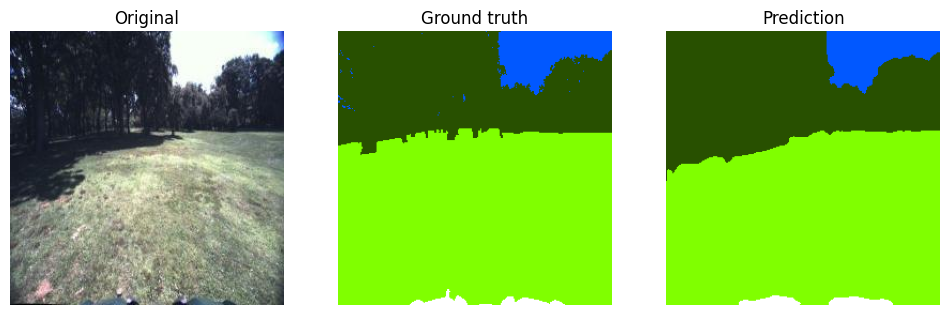

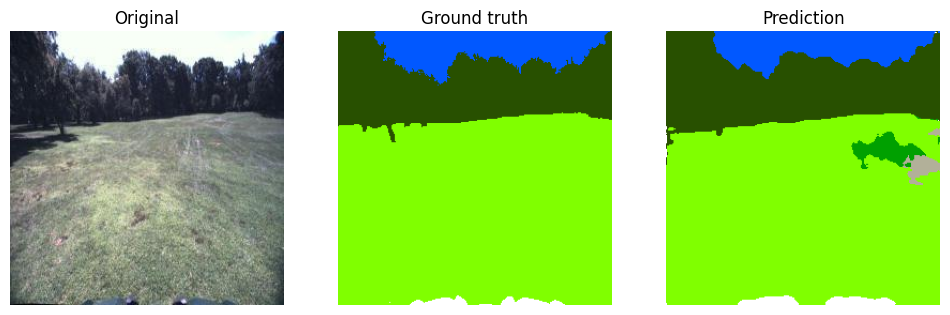

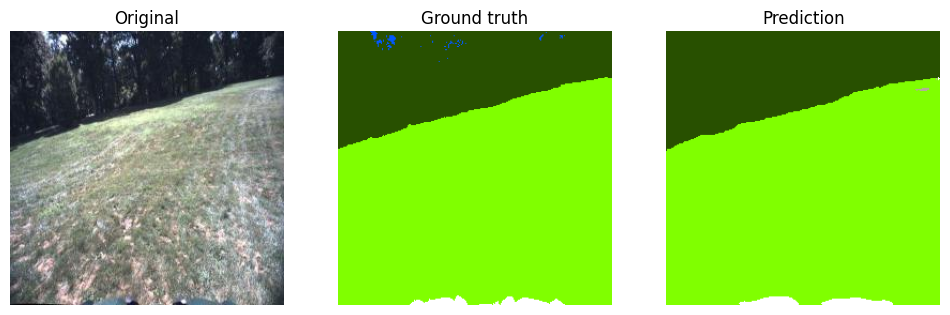

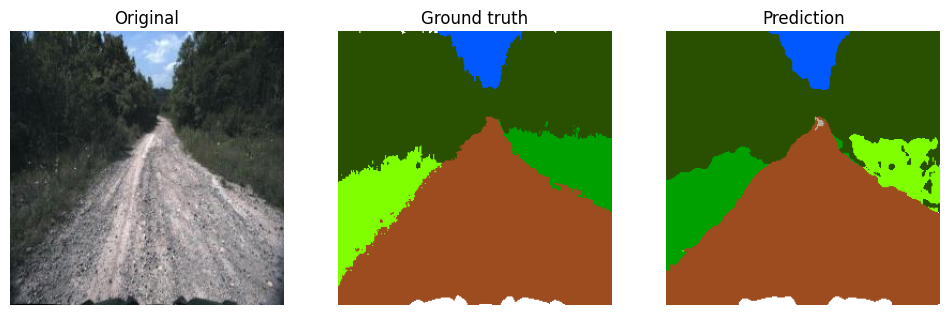

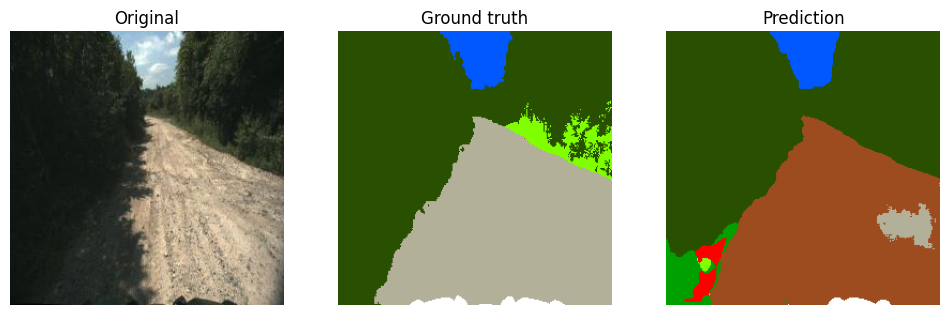

...

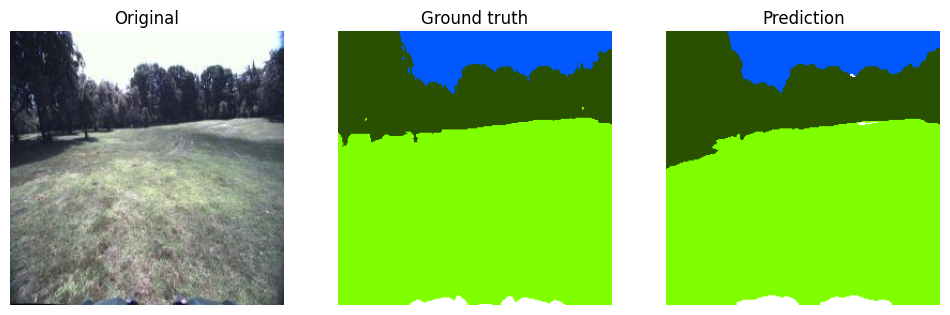

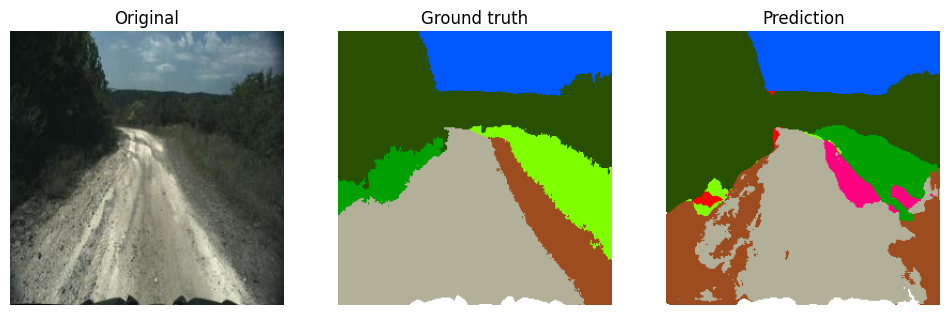

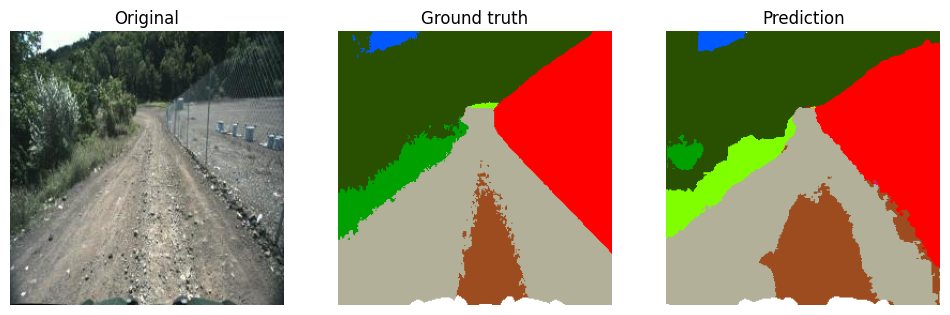

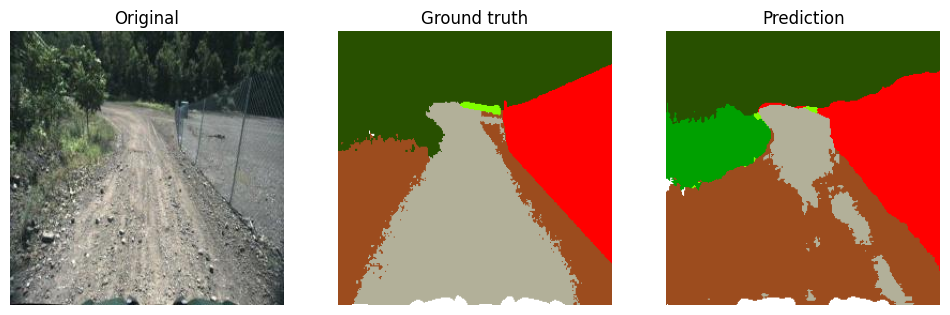

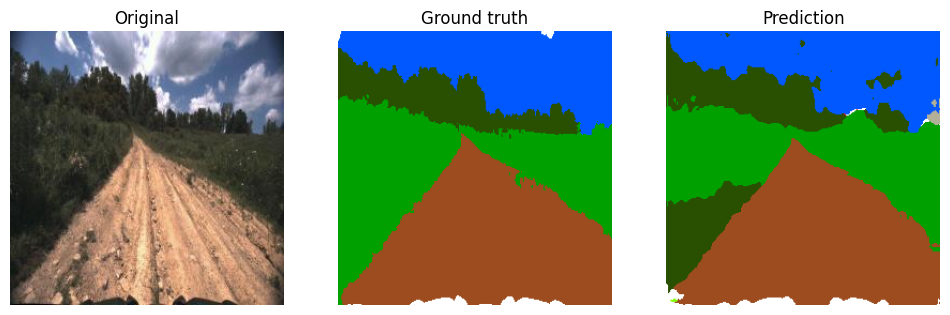

In [157]:
show_many_predictions(model, val_loader, num_imgs=20)

In [161]:
def iou_per_class(pred, true, num_classes):
    pred = pred.cpu( )
    true = true.cpu( )

    ious = [ ]
    for cls in range(num_classes):
        pred_cls = (pred == cls)
        true_cls = (true == cls)

        intersection = (pred_cls & true_cls).sum().item()
        union = (pred_cls | true_cls).sum().item()

        if union == 0:
            ious.append(float('nan'))
        else:
            ious.append(intersection / union)
    return ious

In [162]:
def compute_miou_on_validation(model, val_loader, num_classes):
    model.eval( )
    all_ious = [ ]

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs  = imgs.to(DEVICE)
            masks = masks.to(DEVICE)

            preds = torch.argmax(model(imgs), dim=1)

            # tutto su CPU qui
            preds_cpu = preds.cpu()
            masks_cpu = masks.cpu()

            for i in range(len(preds_cpu)):
                ious = iou_per_class(preds_cpu[i], masks_cpu[i], num_classes)
                all_ious.append(ious)

    all_ious = np.array(all_ious, dtype=np.float32)
    mean_ious = np.nanmean(all_ious, axis=0)
    miou = np.nanmean(mean_ious)

    return miou, mean_ious

In [163]:
miou, class_ious = compute_miou_on_validation(model, val_loader, NUM_CLASSES)

print("📊 Mean IoU:", miou)
print("\nIoU per classe:")
for cls_name, iou in zip(CLASS_NAMES, class_ious):
    print(f"{cls_name:35s}: {iou:.4f}")

📊 Mean IoU: 0.5309776

IoU per classe:
background                         : 0.5286
sky                                : 0.9207
rough_trail                        : 0.2321
smooth_trail                       : 0.8950
traversable_grass                  : 0.8934
high_vegetation                    : 0.7807
non_traversable_low_vegetation     : 0.1528
puddle                             : 0.0000
obstacle                           : 0.3755
